# Ridge/LASSO polynomial regression with linear and random sampling
* Input variable space is constructed using random sampling/cluster pick/uniform sampling
* Linear fit is often inadequate but higher-order polynomial fits often leads to overfitting i.e. learns spurious, flawed relationships between input and output
* Ridge and LASSO regression are used with varying model complexity (degree of polynomial)
* Model score is obtained on a test set and average score over a # of runs is compared for linear and random sampling

### Import libraries

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

### Global variables for the program

In [30]:
N_points = 41 # Number of points for constructing function
x_min = 1 # Min of the range of x (feature)
x_max = 10 # Max of the range of x (feature)
noise_mean = 0 # Mean of the Gaussian noise adder
noise_sd = 2 # Std.Dev of the Gaussian noise adder
ridge_alpha = tuple([10**(x) for x in range(-3,0,1) ]) # Alpha (regularization strength) of ridge regression
lasso_eps = 0.001
lasso_nalpha=20
lasso_iter=1000
degree_min = 2
degree_max = 8

### Generate feature and output vector following a non-linear function
$$ The\ ground\ truth\ or\ originating\ function\ is\ as\ follows:\  $$

$$ y=f(x)= x^2sin(x)e^{-0.1x}+\psi(x),$$
$$ where $$
$$ \psi(x) = {\displaystyle f(x\;|\;\mu ,\sigma ^{2})={\frac {1}{\sqrt {2\pi \sigma ^{2}}}}\;e^{-{\frac {(x-\mu )^{2}}{2\sigma ^{2}}}}} $$

In [31]:
x_smooth = np.array(np.linspace(x_min,x_max,1001))

In [32]:
# Linearly spaced sample points
X=np.array(np.linspace(x_min,x_max,N_points))

# Samples drawn from uniform random distribution
X_sample = x_min+np.random.rand(N_points)*(x_max-x_min)

In [33]:
def func(x):
    result = x**2*np.sin(x)*np.exp(-(1/x_max)*x)
    return (result)

In [34]:
noise_x = np.random.normal(loc=noise_mean,scale=noise_sd,size=N_points)

In [35]:
y = func(X)+noise_x
y_sampled = func(X_sample)+noise_x

In [36]:
df = pd.DataFrame(data=X,columns=['X'])
df['Ideal y']=df['X'].apply(func)
df['y']=y
df['X_sampled']=X_sample
df['y_sampled']=y_sampled
df.head()

,X,Ideal y,y,X_sampled,y_sampled
0,1.000,0.761394,-0.869111,4.529045,-14.453185
1,1.225,1.249025,1.155362,8.023615,28.350966
2,1.450,1.805456,1.731301,8.533276,24.059596
3,1.675,2.360061,4.259558,8.009152,30.350034
4,1.900,2.825011,-1.587071,8.491415,20.375640


### Plot the function(s), both the ideal characteristic and the observed output (with process and observation noise)

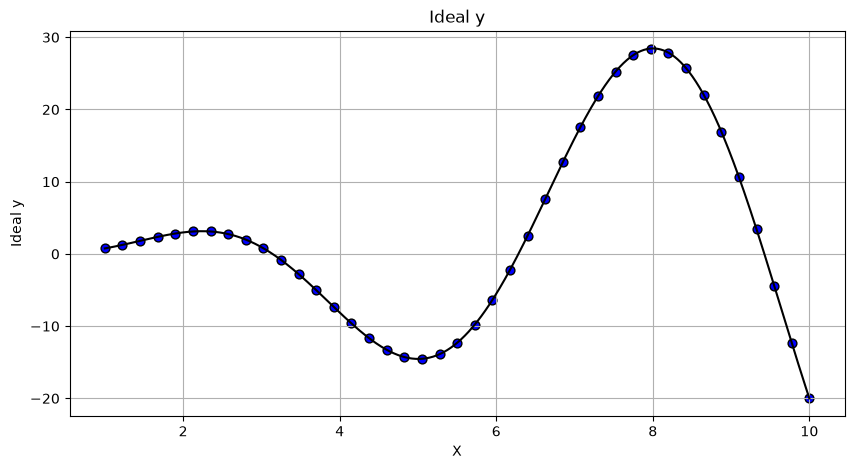

In [37]:
df.plot.scatter('X','Ideal y',title='Ideal y',grid=True,edgecolors=(0,0,0),c='blue',s=40,figsize=(10,5))
plt.plot(x_smooth,func(x_smooth),'k')

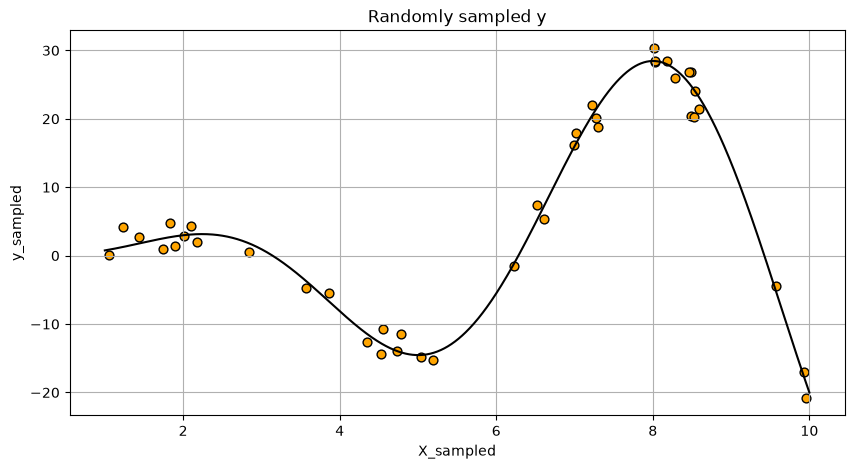

In [38]:
df.plot.scatter('X_sampled',y='y_sampled',title='Randomly sampled y',
                grid=True,edgecolors=(0,0,0),c='orange',s=40,figsize=(10,5))
plt.plot(x_smooth,func(x_smooth),'k')

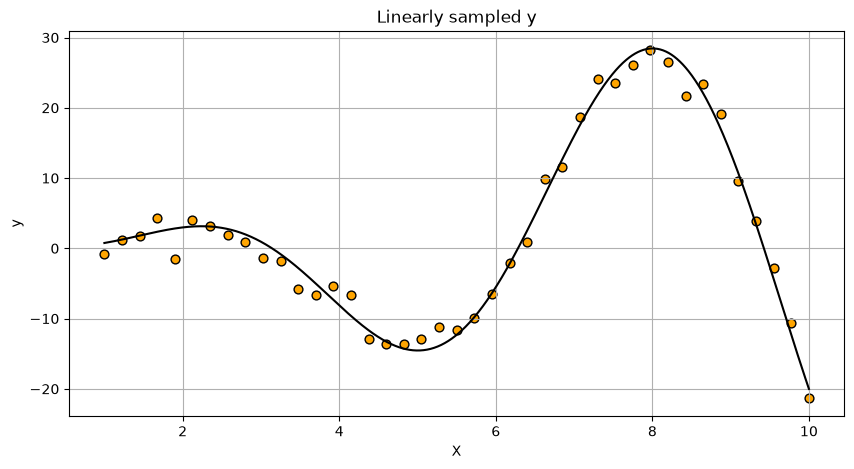

In [39]:
df.plot.scatter('X',y='y',title='Linearly sampled y',grid=True,edgecolors=(0,0,0),c='orange',s=40,figsize=(10,5))
plt.plot(x_smooth,func(x_smooth),'k')

### Import scikit-learn librares and prepare train/test splits

In [40]:
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline

In [41]:
X_train, X_test, y_train, y_test = train_test_split(df['X'], df['y'], test_size=0.33)
X_train=X_train.values.reshape(-1,1)
X_test=X_test.values.reshape(-1,1)

### Polynomial model with Ridge regularization (pipelined) with lineary spaced samples
** This is an advanced machine learning method which prevents over-fitting by penalizing high-valued coefficients i.e. keep them bounded **

In [42]:
linear_sample_score = []
poly_degree = []
for degree in range(degree_min,degree_max+1):
    model = make_pipeline(PolynomialFeatures(degree), RidgeCV(alphas=ridge_alpha,cv=5))
    model.fit(X_train, y_train)
    poly_degree.append(degree)
    linear_sample_score.append(model.score(X_test, y_test))

c:\Users\Hamidur\Documents\LUT_exercises\AI_ML\.venv\Lib\site-packages\sklearn\linear_model\_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 1.1611607548466028e-17.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
c:\Users\Hamidur\Documents\LUT_exercises\AI_ML\.venv\Lib\site-packages\sklearn\linear_model\_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 1.53962351398556e-17.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
c:\Users\Hamidur\Documents\LUT_exercises\AI_ML\.venv\Lib\site-packages\sklearn\linear_model\_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 6.327926304352575e-18.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
c:\Users\Hamidur\Documents\LUT_exercises\AI_ML\.venv\Lib\site-packages\sklearn\linear_model\_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 8.178121250171038e-18.
 

In [43]:
linear_sample_score

[-0.24549658203798885,
 0.47844905555104267,
 0.9017632671215192,
 0.8011569195801587,
 0.9512214130356558,
 0.8957672108354107,
 0.922314263020981]

### Modeling with randomly sampled data set

In [44]:
X_train, X_test, y_train, y_test = train_test_split(df['X_sampled'], df['y_sampled'], test_size=0.33)
X_train=X_train.values.reshape(-1,1)
X_test=X_test.values.reshape(-1,1)

In [45]:
random_sample_score = []
poly_degree = []
for degree in range(degree_min,degree_max+1):
    model = make_pipeline(PolynomialFeatures(degree), RidgeCV(alphas=ridge_alpha,cv=5))
    model.fit(X_train, y_train)
    poly_degree.append(degree)
    random_sample_score.append(model.score(X_test, y_test))

c:\Users\Hamidur\Documents\LUT_exercises\AI_ML\.venv\Lib\site-packages\sklearn\linear_model\_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 1.1063440787596595e-17.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
c:\Users\Hamidur\Documents\LUT_exercises\AI_ML\.venv\Lib\site-packages\sklearn\linear_model\_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 4.666209701032696e-18.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
c:\Users\Hamidur\Documents\LUT_exercises\AI_ML\.venv\Lib\site-packages\sklearn\linear_model\_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 5.065701235882235e-18.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
c:\Users\Hamidur\Documents\LUT_exercises\AI_ML\.venv\Lib\site-packages\sklearn\linear_model\_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 4.83198961786784e-18.
 

In [46]:
random_sample_score

[0.2157958194090347,
 0.76539133698954,
 0.9486080063637985,
 0.9297613325331767,
 0.972665596975933,
 0.9761213443809568,
 0.9781668268374556]

In [47]:
df_score = pd.DataFrame(data={'degree':poly_degree,
                              'Linear sample score':linear_sample_score,
                              'Random sample score':random_sample_score})
df_score

,degree,Linear sample score,Random sample score
0,2,-0.245497,0.215796
1,3,0.478449,0.765391
2,4,0.901763,0.948608
3,5,0.801157,0.929761
4,6,0.951221,0.972666
5,7,0.895767,0.976121
6,8,0.922314,0.978167


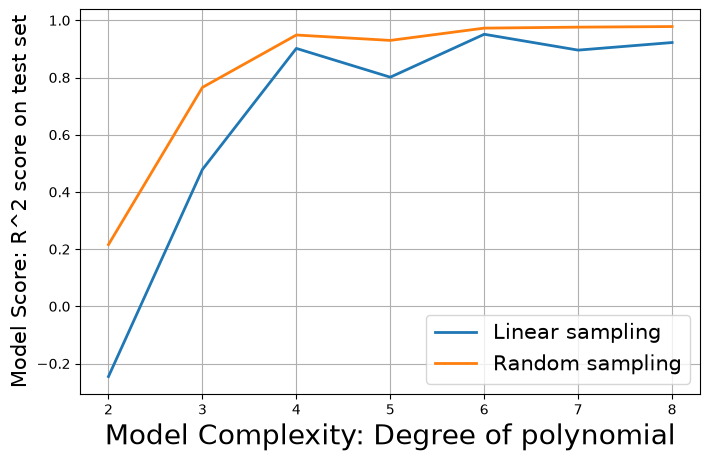

In [48]:
plt.figure(figsize=(8,5))
plt.grid(True)
plt.plot(df_score['degree'],df_score['Linear sample score'],lw=2,label='Linear sampling')
plt.plot(df_score['degree'],df_score['Random sample score'],lw=2,label='Random sampling')
plt.xlabel ("Model Complexity: Degree of polynomial",fontsize=20)
plt.ylabel ("Model Score: R^2 score on test set",fontsize=15)
plt.legend(fontsize=15)